# Spike fade on minute data, out of sample

**Goal.** Retest the regular-hours spike fade on the minute archive. Treat 2024-07-07 onward as in-sample, because that is the window where the pattern was found. Everything earlier is out of sample.

**Method.** Hourly bars from `data/nq_1m_front.parquet` (`src.bars`). Returns are dropped when the contract changes. A signal is an RTH hour (9:00–14:00 New York) with return above 2 trailing standard deviations, and a next bar exactly one hour later on the same contract (`src.signals`). The short is entered at that hour's close and managed on the next hour's minute bars (`src.simulate`): time exit, or a stop at 2 hourly standard deviations, or that stop plus a target at 1 standard deviation. Same-minute stop and target assumes the stop. Costs match notebook 06: 2 MNQ, $2 per point, $1.50 per contract round trip, 1 point slippage, $1,000 daily loss limit. The walk-forward rule in the next cell turns a month on only when the previous 100 trades averaged more than 0 points at the start of the month.

**Result.** Time exit, out of sample: 801 trades, 43% wins, -1.1 pts, -$5,995, profit factor 0.90. In sample: 247 trades, 55% wins, +13.6 pts, +$12,656, profit factor 1.46. The stop variants agree on the sign. Next-hour direction was down 45.8% out of sample and 55.6% in sample. By year, 2026 is +28.4 pts per trade and most of the in-sample profit. The monthly filter made +$9,286 versus +$6,661 always-on.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


=== Pattern check: next-hour pullback after an RTH spike ===
Out-of-sample 2017-2024   802 signals | next hour down 45.8% | avg pullback -0.4 pts
In-sample 2024-2026       248 signals | next hour down 55.6% | avg pullback +14.7 pts

Time exit only  (outcomes: {'time exit': 1048})
  Out-of-sample 2017-24     801 trades | win 43% | avg   -1.1 pts | P&L $   -5,995 | PF 0.90 | max DD $-8,484
  In-sample 2024-26         247 trades | win 55% | avg  +13.6 pts | P&L $  +12,656 | PF 1.46 | max DD $-3,180

Stop 2 sigma, time exit  (outcomes: {'time exit': 852, 'stop': 197})
  Out-of-sample 2017-24     801 trades | win 42% | avg   -1.4 pts | P&L $   -6,790 | PF 0.88 | max DD $-8,657
  In-sample 2024-26         248 trades | win 54% | avg  +12.8 pts | P&L $  +11,939 | PF 1.44 | max DD $-3,852

Stop 2 sigma, target 1 sigma  (outcomes: {'target': 491, 'time exit': 379, 'stop': 180})
  Out-of-sample 2017-24     802 trades | win 52% | avg   -2.9 pts | P&L $  -11,699 | PF 0.77 | max DD $-11,853
  In-sam

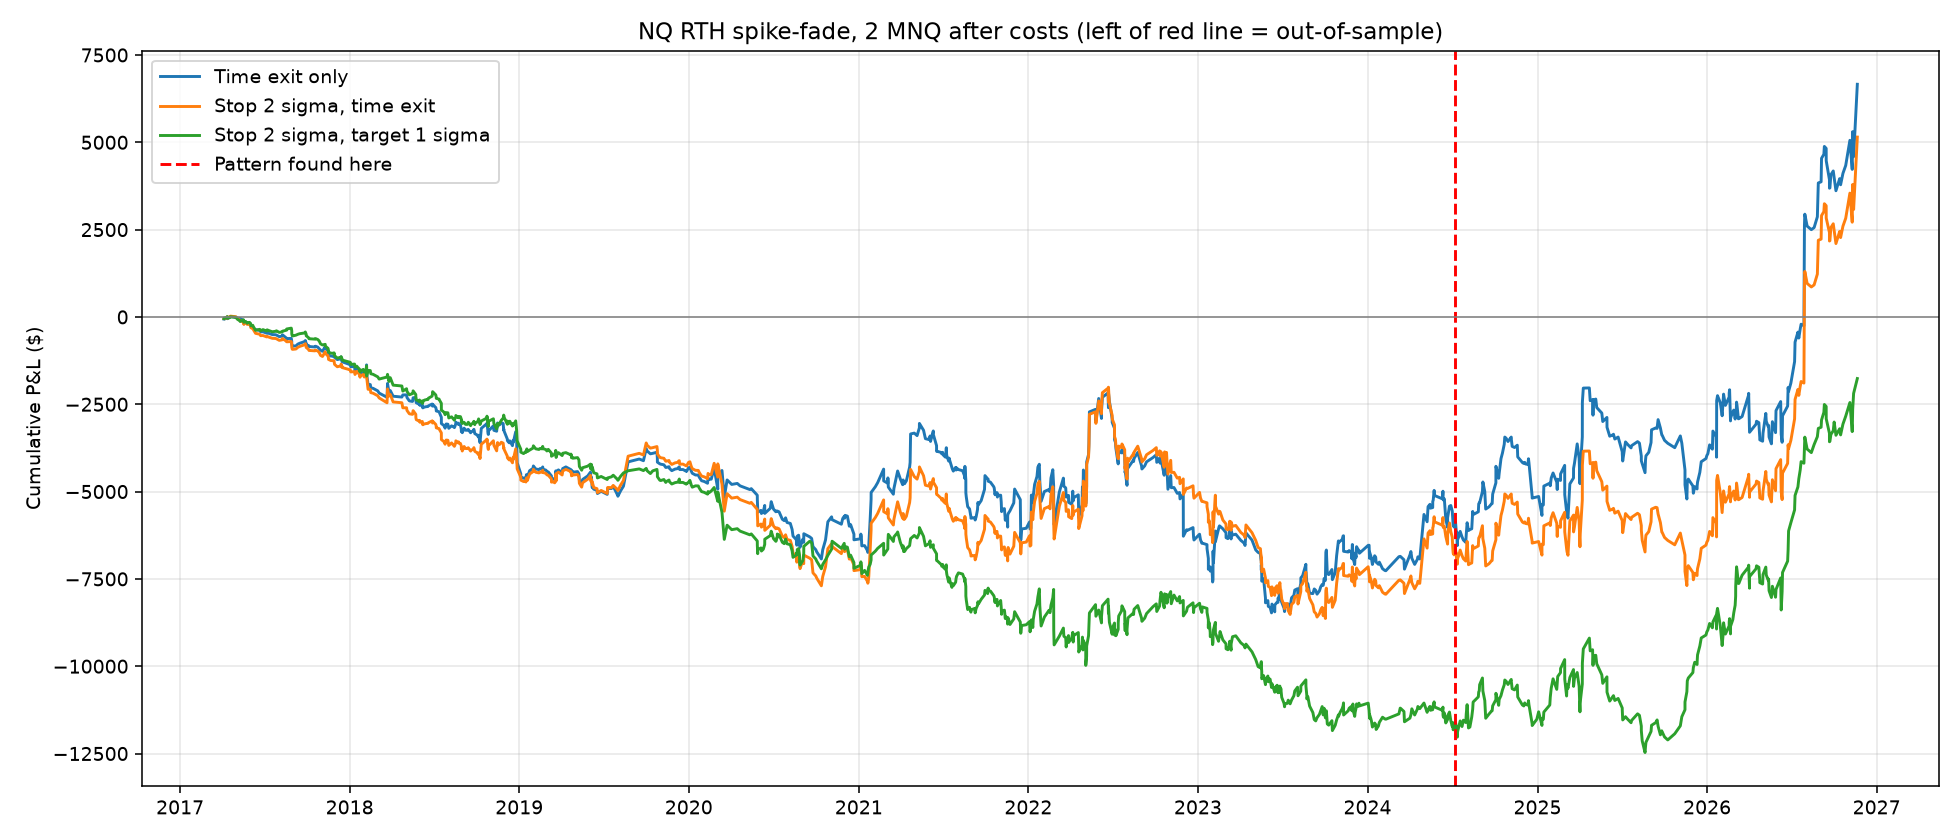

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.bars import build_hourly_bars
from src.signals import add_return_zscore, rth_up_spike_signals
from src.simulate import simulate_minute
from src.performance import summary, yearly_summary

nq = pd.read_parquet(ROOT / "data" / "nq_1m_front.parquet")
discovery_start = pd.Timestamp("2024-07-07", tz="America/New_York")

hourly = add_return_zscore(build_hourly_bars(nq))
sig = rth_up_spike_signals(hourly)
sig["oos"] = sig["hour"] < discovery_start

print("=== Pattern check: next-hour pullback after an RTH spike ===")
for name, group in [("Out-of-sample 2017-2024", sig[sig.oos]), ("In-sample 2024-2026", sig[~sig.oos])]:
    print(f"{name:24} {len(group):4} signals | next hour down {(group.move_pts > 0).mean():.1%} "
          f"| avg pullback {group.move_pts.mean():+.1f} pts")

configs = {
    "Time exit only": (None, None),
    "Stop 2 sigma, time exit": (2, None),
    "Stop 2 sigma, target 1 sigma": (2, 1),
}
results = {}
for name, (stop_sigma, target_sigma) in configs.items():
    trades = simulate_minute(nq, sig, stop_sigma=stop_sigma, target_sigma=target_sigma)
    trades["oos"] = trades["time"] < discovery_start
    results[name] = trades
    print(f"\n{name}  (outcomes: {trades.outcome.value_counts().to_dict()})")
    summary(trades[trades.oos], "  Out-of-sample 2017-24")
    summary(trades[~trades.oos], "  In-sample 2024-26")

print("\nTime exit only, by year:")
yearly_summary(results["Time exit only"])

plt.figure(figsize=(14, 6))
for name, trades in results.items():
    plt.plot(trades.time, trades.pnl.cumsum(), label=name)
plt.axvline(discovery_start, color="red", linestyle="--", label="Pattern found here")
plt.axhline(0, color="gray", linewidth=0.8)
plt.title("NQ RTH spike-fade, 2 MNQ after costs (left of red line = out-of-sample)")
plt.ylabel("Cumulative P&L ($)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(ROOT / "results" / "equity_minute.png", dpi=140)
plt.show()


In [3]:
from src.performance import walk_forward_month_filter

trades = walk_forward_month_filter(results["Time exit only"])
active = trades[trades.active]
print(f"Walk-forward: traded {len(active)} of {len(trades)} signals")
for year, group in active.groupby(active.time.dt.year):
    print(f"  {year}: {len(group):3} trades | avg {group.pts.mean():+6.1f} pts | P&L ${group.pnl.sum():+,.0f}")
print(f"Total: ${active.pnl.sum():+,.0f}  vs  always-on: ${trades.pnl.sum():+,.0f}")
ex_2026 = active[active.time.dt.year.between(2020, 2025)]
print(f"2020-2025, excluding 2026: ${ex_2026.pnl.sum():+,.0f}")


Walk-forward: traded 451 of 1048 signals
  2020:  11 trades | avg   +1.2 pts | P&L $+22
  2021:  89 trades | avg   -1.2 pts | P&L $-687
  2022:  69 trades | avg   -6.1 pts | P&L $-1,895
  2023:  13 trades | avg   -4.7 pts | P&L $-285
  2024: 101 trades | avg   +5.4 pts | P&L $+1,867
  2025:  83 trades | avg   +2.3 pts | P&L $+511
  2026:  85 trades | avg  +29.4 pts | P&L $+9,753
Total: $+9,286  vs  always-on: $+6,661
2020-2025, excluding 2026: $-467


Out of sample (before 2024-07-07) the fade is not profitable under any of the three exit rules. In sample it is, and 2026 carries most of that profit. The monthly walk-forward filter avoids 2017-2019, loses money on the 2021-2022 false starts, and still depends on 2026 for the total. That is not a stable historical edge.
